In [1]:
# Imports + load Fashion-MNIST (Task 3-4)

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, regularizers
from tensorflow.keras.datasets import fashion_mnist

np.random.seed(42)
tf.random.set_seed(42)

(x_train, _), (x_test, _) = fashion_mnist.load_data()

x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

print("x_train:", x_train.shape, "x_test:", x_test.shape)
print("min/max:", x_train.min(), x_train.max())


x_train: (60000, 28, 28) x_test: (10000, 28, 28)
min/max: 0.0 1.0


In [2]:
# Sparse Autoencoder (L1 on latent) - build + train

x_train_flat = x_train.reshape((len(x_train), 784))
x_test_flat  = x_test.reshape((len(x_test), 784))

encoding_dim = 64
l1_strength = 1e-5  # small but effective

input_img = layers.Input(shape=(784,))

encoded = layers.Dense(
    encoding_dim,
    activation="relu",
    activity_regularizer=regularizers.l1(l1_strength),
    name="latent_sparse"
)(input_img)

decoded = layers.Dense(784, activation="sigmoid")(encoded)

sparse_ae = tf.keras.Model(input_img, decoded, name="sparse_autoencoder")
sparse_ae.compile(optimizer="adam", loss="mse")

sparse_ae.summary()

history_sparse = sparse_ae.fit(
    x_train_flat, x_train_flat,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_flat, x_test_flat),
    verbose=1
)

test_loss_sparse = sparse_ae.evaluate(x_test_flat, x_test_flat, verbose=0)
print("Sparse AE Test Loss:", test_loss_sparse)


Model: "sparse_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_sparse (Dense)           │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 784)            │        50,960 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,200 (395.31 KB)

 Trainable params: 101,200 (395.31 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.1585 - val_loss: 0.1465
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1385 - val_loss: 0.1302
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1230 - val_loss: 0.1036
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0948 - val_loss: 0.0897
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0874 - val_loss: 0.0846
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0830 - val_loss: 0.0807
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0794 - val_loss: 0.0773
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0763 - val_loss: 0.0745
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0737 - val_loss: 0.0723
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0716 - val_loss: 0.0704
Sparse AE Test Loss: 0.06764078140258789


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


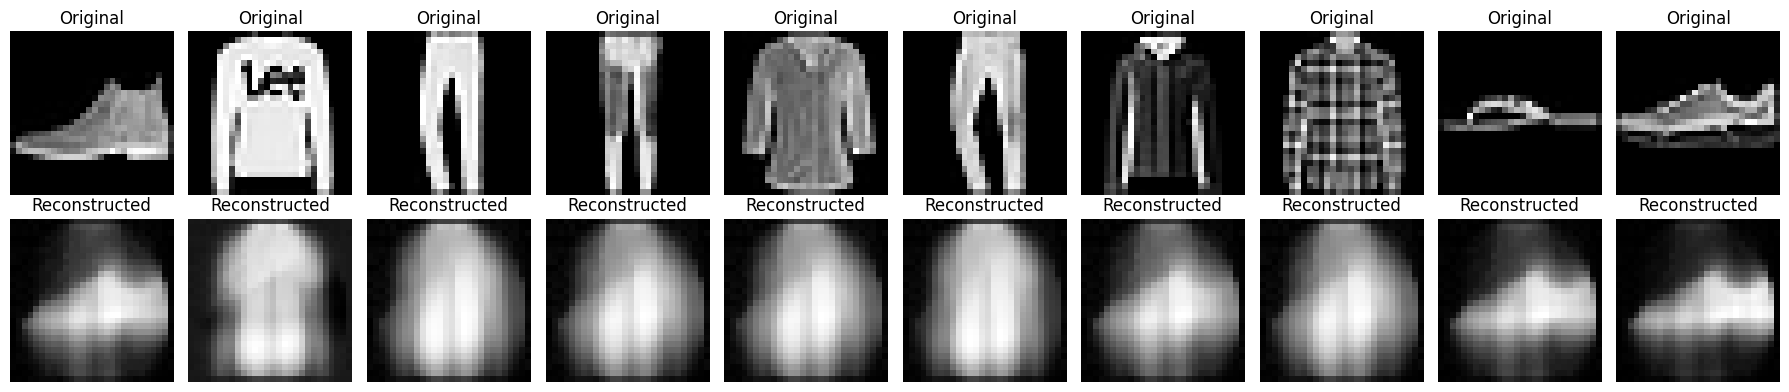

In [3]:
# Sparse AE reconstructions (original vs reconstructed)

decoded_sparse = sparse_ae.predict(x_test_flat)

n = 10
plt.figure(figsize=(18, 4))
for i in range(n):
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title("Original")
    plt.axis("off")

    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(decoded_sparse[i].reshape(28, 28), cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [4]:
# Add noise to images (train noisy → clean)

noise_factor = 0.3

x_train_noisy = x_train + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_train.shape)
x_test_noisy  = x_test  + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)

# clip back to [0,1]
x_train_noisy = np.clip(x_train_noisy, 0.0, 1.0)
x_test_noisy  = np.clip(x_test_noisy, 0.0, 1.0)

print("Noisy min/max:", x_train_noisy.min(), x_train_noisy.max())


Noisy min/max: 0.0 1.0


In [5]:
# Denoising Autoencoder (Conv) - build + train

x_train_noisy_cnn = x_train_noisy.reshape(-1, 28, 28, 1)
x_test_noisy_cnn  = x_test_noisy.reshape(-1, 28, 28, 1)

x_train_clean_cnn = x_train.reshape(-1, 28, 28, 1)
x_test_clean_cnn  = x_test.reshape(-1, 28, 28, 1)

denoise = tf.keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2), padding="same"),
    layers.Conv2D(16, (3,3), activation="relu", padding="same"),
    layers.MaxPooling2D((2,2), padding="same"),

    layers.Conv2DTranspose(16, (3,3), strides=2, activation="relu", padding="same"),
    layers.Conv2DTranspose(32, (3,3), strides=2, activation="relu", padding="same"),
    layers.Conv2D(1, (3,3), activation="sigmoid", padding="same")
], name="denoising_autoencoder")

denoise.compile(optimizer="adam", loss="mse")
denoise.summary()

history_denoise = denoise.fit(
    x_train_noisy_cnn, x_train_clean_cnn,
    epochs=10,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_noisy_cnn, x_test_clean_cnn),
    verbose=1
)

test_loss_denoise = denoise.evaluate(x_test_noisy_cnn, x_test_clean_cnn, verbose=0)
print("Denoising AE Test Loss:", test_loss_denoise)


Model: "denoising_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 16)     │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 16)     │         2,320 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │         4,640 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,193 (47.63 KB)

 Trainable params: 12,193 (47.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 26s 105ms/step - loss: 0.0432 - val_loss: 0.0186
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 26s 109ms/step - loss: 0.0170 - val_loss: 0.0159
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - loss: 0.0150 - val_loss: 0.0145
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 91ms/step - loss: 0.0139 - val_loss: 0.0137
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 21s 90ms/step - loss: 0.0132 - val_loss: 0.0131
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 95ms/step - loss: 0.0127 - val_loss: 0.0127
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 92ms/step - loss: 0.0124 - val_loss: 0.0124
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 93ms/step - loss: 0.0121 - val_loss: 0.0121
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 94ms/step - loss: 0.0118 - val_loss: 0.0118
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 93ms/step - loss: 0.0116 - val_loss: 0.0116
Denoising AE Test Loss: 0.011613585986196995


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step


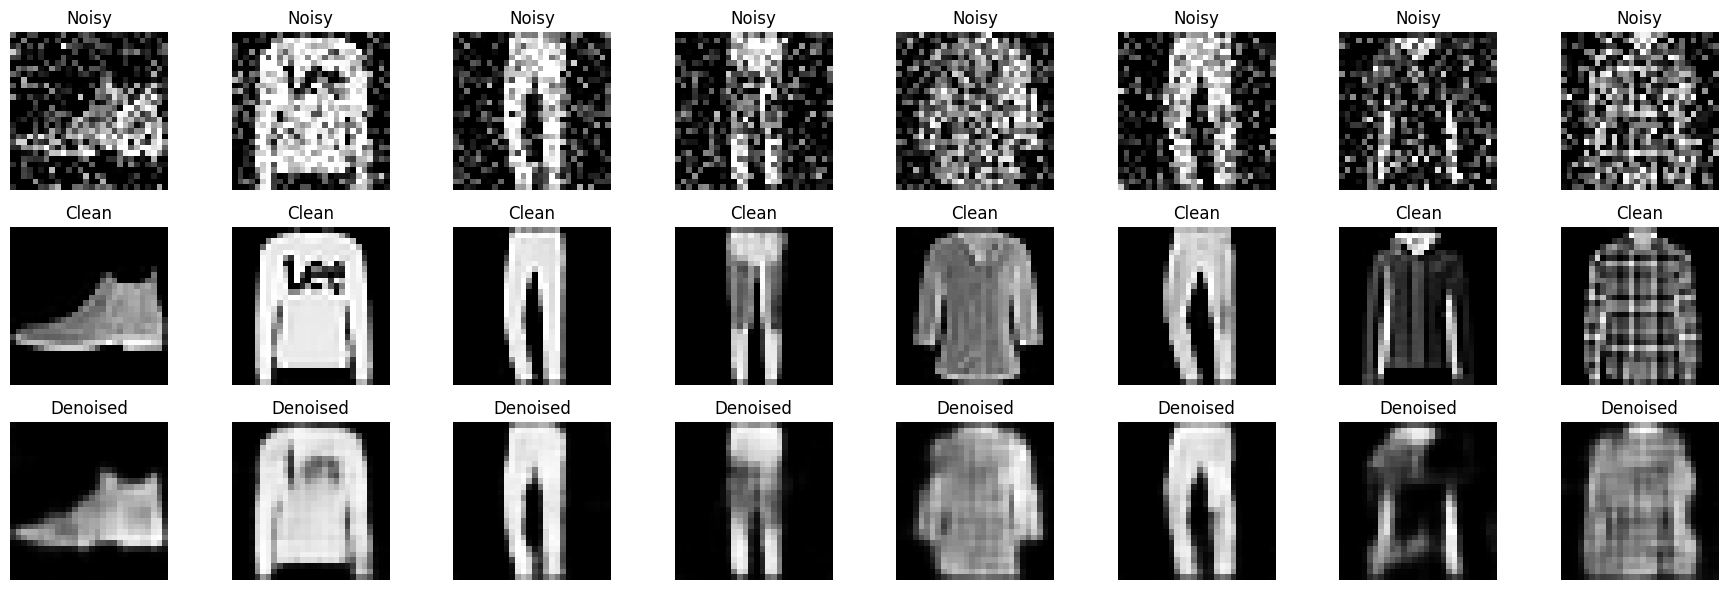

In [6]:
# Denoising results (Noisy vs Clean vs Denoised)

decoded = denoise.predict(x_test_noisy_cnn)

n = 8
plt.figure(figsize=(18, 6))

for i in range(n):
    # noisy
    ax = plt.subplot(3, n, i + 1)
    plt.imshow(x_test_noisy[i], cmap="gray")
    plt.title("Noisy")
    plt.axis("off")

    # clean
    ax = plt.subplot(3, n, i + 1 + n)
    plt.imshow(x_test[i], cmap="gray")
    plt.title("Clean")
    plt.axis("off")

    # denoised
    ax = plt.subplot(3, n, i + 1 + 2*n)
    plt.imshow(decoded[i].reshape(28, 28), cmap="gray")
    plt.title("Denoised")
    plt.axis("off")

plt.tight_layout()
plt.show()
